In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


In [2]:
from google.colab import files
uploaded = files.upload()  # Selecciona el archivo 'default of credit card clients.csv'

Saving default of credit card clients.csv to default of credit card clients.csv


In [3]:
# Cargamos el archivo ajustando el separador y la fila de cabecera
file_path = 'default of credit card clients.csv'
df = pd.read_csv(file_path, sep=';', header=1)


In [4]:
df.shape


(30000, 25)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_A

In [6]:
# Corregir la inconsistencia de nombres
df.rename(columns={'PAY_0': 'PAY_1'}, inplace=True)

# Ahora todas las series van de 1 a 6 de forma homogénea:
# PAY_1 a PAY_6
# BILL_AMT1 a BILL_AMT6
# PAY_AMT1 a PAY_AMT6

In [7]:
df.head(10)

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0
5,6,50000,1,1,2,37,0,0,0,0,...,19394,19619,20024,2500,1815,657,1000,1000,800,0
6,7,500000,1,1,2,29,0,0,0,0,...,542653,483003,473944,55000,40000,38000,20239,13750,13770,0
7,8,100000,2,2,2,23,0,-1,-1,0,...,221,-159,567,380,601,0,581,1687,1542,0
8,9,140000,2,3,1,28,0,0,2,0,...,12211,11793,3719,3329,0,432,1000,1000,1000,0
9,10,20000,1,3,2,35,-2,-2,-2,-2,...,0,13007,13912,0,0,0,13007,1122,0,0


In [8]:
df.head(5).T

,0,1,2,3,4
ID,1,2,3,4,5
LIMIT_BAL,20000,120000,90000,50000,50000
SEX,2,2,2,2,1
EDUCATION,2,2,2,2,2
MARRIAGE,1,2,2,1,1
AGE,24,26,34,37,57
PAY_1,2,-1,0,0,-1
PAY_2,2,2,0,0,0
PAY_3,-1,0,0,0,-1
PAY_4,-1,0,0,0,0


In [9]:
df.isna().sum()

,0
ID,0
LIMIT_BAL,0
SEX,0
EDUCATION,0
MARRIAGE,0
AGE,0
PAY_1,0
PAY_2,0
PAY_3,0
PAY_4,0


In [10]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_1,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0


In [11]:
pay_cols = ['PAY_1', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']

# Cuenta la frecuencia de cada valor en las 6 columnas
frecuencias = df[pay_cols].apply(pd.Series.value_counts).fillna(0).astype(int)
frecuencias.sort_index()

,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6
-2,2759,3782,4085,4348,4546,4895
-1,5686,6050,5938,5687,5539,5740
0,14737,15730,15764,16455,16947,16286
1,3688,28,4,2,0,0
2,2667,3927,3819,3159,2626,2766
3,322,326,240,180,178,184
4,76,99,76,69,84,49
5,26,25,21,35,17,13
6,11,12,23,5,4,19
7,9,20,27,58,58,46


In [12]:
# Comparamos la factura (BILL_AMT1) y el pago realizado (PAY_AMT1) por cada valor de PAY_1
df.groupby('PAY_1')[['BILL_AMT1', 'PAY_AMT1']].agg(['count', 'median']).round(2)

BILL_AMT1           PAY_AMT1        
          count    median    count  median
PAY_1                                     
-2         2759    1179.0     2759  1131.0
-1         5686    2739.5     5686  1732.5
 0        14737   49605.0    14737  3000.0
 1         3688    4606.5     3688     0.0
 2         2667   41632.0     2667  2000.0
 3          322   18354.0      322     0.0
 4           76   31633.0       76     0.0
 5           26   39752.5       26     0.0
 6           11   71310.0       11     0.0
 7            9  126220.0        9     0.0
 8           19   43340.0       19     0.0

In [13]:
df.groupby('PAY_2')[['BILL_AMT2', 'PAY_AMT2']].agg(['count', 'median']).round(2)

BILL_AMT2          PAY_AMT2        
          count   median    count  median
PAY_2                                    
-2         3782      0.0     3782   190.5
-1         6050   2035.0     6050  1562.5
 0        15730  48428.0    15730  2772.5
 1           28   -338.0       28   537.0
 2         3927  27689.0     3927  1646.0
 3          326  24481.0      326     0.0
 4           99  27371.0       99     0.0
 5           25  37936.0       25     0.0
 6           12  77765.0       12     0.0
 7           20  39860.5       20     0.0
 8            1  25589.0        1     0.0

In [14]:
df.groupby('PAY_3')[['BILL_AMT3', 'PAY_AMT3']].agg(['count', 'median']).round(2)

BILL_AMT3          PAY_AMT3        
          count   median    count  median
PAY_3                                    
-2         4085      0.0     4085     0.0
-1         5938   2252.5     5938  1390.0
 0        15764  46893.5    15764  2200.0
 1            4  68485.0        4  4435.0
 2         3819  26305.0     3819  1231.0
 3          240  20441.0      240     0.0
 4           76  31448.0       76     0.0
 5           21  32308.0       21     0.0
 6           23  33756.0       23     0.0
 7           27   2400.0       27     0.0
 8            3  21936.0        3     0.0

In [15]:
df.groupby('PAY_4')[['BILL_AMT4', 'PAY_AMT4']].agg(['count', 'median']).round(2)

BILL_AMT4           PAY_AMT4        
          count    median    count  median
PAY_4                                     
-2         4348       0.0     4348     0.0
-1         5687    2156.0     5687  1132.0
 0        16455   38465.0    16455  2000.0
 1            2  185766.0        2  7550.0
 2         3159   28380.0     3159  1100.0
 3          180   27332.5      180     0.0
 4           69   20779.0       69     0.0
 5           35   22757.0       35     0.0
 6            5   24579.0        5     0.0
 7           58    2400.0       58     0.0
 8            2   29107.5        2     0.0

In [16]:
df.groupby('PAY_5')[['BILL_AMT5', 'PAY_AMT5']].agg(['count', 'median']).round(2)

BILL_AMT5          PAY_AMT5        
          count   median    count  median
PAY_5                                    
-2         4546      0.0     4546     0.0
-1         5539   1954.0     5539  1170.0
 0        16947  31032.0    16947  2000.0
 2         2626  30477.5     2626  1457.5
 3          178  20031.0      178     0.0
 4           84  21629.0       84     0.0
 5           17  22192.0       17     0.0
 6            4  11413.0        4     0.0
 7           58   2400.0       58     0.0
 8            1   2400.0        1     0.0

In [17]:
df.groupby('PAY_6')[['BILL_AMT6', 'PAY_AMT6']].agg(['count', 'median']).round(2)

BILL_AMT6          PAY_AMT6        
          count   median    count  median
PAY_6                                    
-2         4895      0.0     4895     0.0
-1         5740   1881.5     5740  1140.5
 0        16286  31268.0    16286  2000.0
 2         2766  30491.5     2766  1300.0
 3          184  19367.0      184     0.0
 4           49  16780.0       49     0.0
 5           13  18646.0       13     0.0
 6           19   1950.0       19     0.0
 7           46   2400.0       46     0.0
 8            2  52961.0        2     0.0

In [18]:
df['EDUCATION'].value_counts()

,count
EDUCATION,
2,14030
1,10585
3,4917
5,280
4,123
6,51
0,14


Esta mal puesto, la base explica que la educacion va de 1 a 4. No existe ni 0,5,6. Habria que ver de depurar la base

In [19]:
df['MARRIAGE'].value_counts()

,count
MARRIAGE,
2,15964
1,13659
3,323
0,54


Esta mal puesto, la base explica que la educacion va de 1 a 3. No existe 0

DECISION: en education cambiamos tanto 0,5,6 por 4 (others)
en marriage cambiamos 0 por 3 (others)

In [20]:
df['EDUCATION'] = df['EDUCATION'].replace({0: 4, 5: 4, 6: 4})
df['MARRIAGE'] = df['MARRIAGE'].replace({0: 3})

In [21]:
df['EDUCATION'].value_counts()

,count
EDUCATION,
2,14030
1,10585
3,4917
4,468


In [22]:
df['MARRIAGE'].value_counts()

,count
MARRIAGE,
2,15964
1,13659
3,377


In [23]:
# 2. Mapeo a etiquetas legibles
mapeo_sexo = {1: 'Hombre', 2: 'Mujer'}
mapeo_edu = {1: 'Posgrado', 2: 'Universidad', 3: 'Secundaria', 4: 'Otros'}
mapeo_matr = {1: 'Casado', 2: 'Soltero', 3: 'Otros'}
df['SEX_DESC'] = df['SEX'].map(mapeo_sexo)
df['EDU_DESC'] = df['EDUCATION'].map(mapeo_edu)
df['MARRIAGE_DESC'] = df['MARRIAGE'].map(mapeo_matr)

In [24]:
target = 'default payment next month'

for col in ['SEX_DESC', 'EDU_DESC', 'MARRIAGE_DESC']:
    resumen = df.groupby(col)[target].agg(
        Total='count',
        Defaults='sum',
        Tasa_Default=lambda x: f"{(x.mean() * 100):.2f}%"
    ).sort_values(by='Total', ascending=False)

    print(f"\n--- Análisis por: {col} ---")
    display(resumen)


--- Análisis por: SEX_DESC ---


,Total,Defaults,Tasa_Default
SEX_DESC,,,
Mujer,18112,3763,20.78%
Hombre,11888,2873,24.17%



--- Análisis por: EDU_DESC ---


,Total,Defaults,Tasa_Default
EDU_DESC,,,
Universidad,14030,3330,23.73%
Posgrado,10585,2036,19.23%
Secundaria,4917,1237,25.16%
Otros,468,33,7.05%



--- Análisis por: MARRIAGE_DESC ---


,Total,Defaults,Tasa_Default
MARRIAGE_DESC,,,
Soltero,15964,3341,20.93%
Casado,13659,3206,23.47%
Otros,377,89,23.61%


/tmp/ipykernel_2676/2947261561.py:4: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x=col, y=target, ax=axes[i], ci=None, palette='Blues_d')
/tmp/ipykernel_2676/2947261561.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x=col, y=target, ax=axes[i], ci=None, palette='Blues_d')
/tmp/ipykernel_2676/2947261561.py:4: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x=col, y=target, ax=axes[i], ci=None, palette='Blues_d')
/tmp/ipykernel_2676/2947261561.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x=col, y=target, ax=axes[i], ci=None,

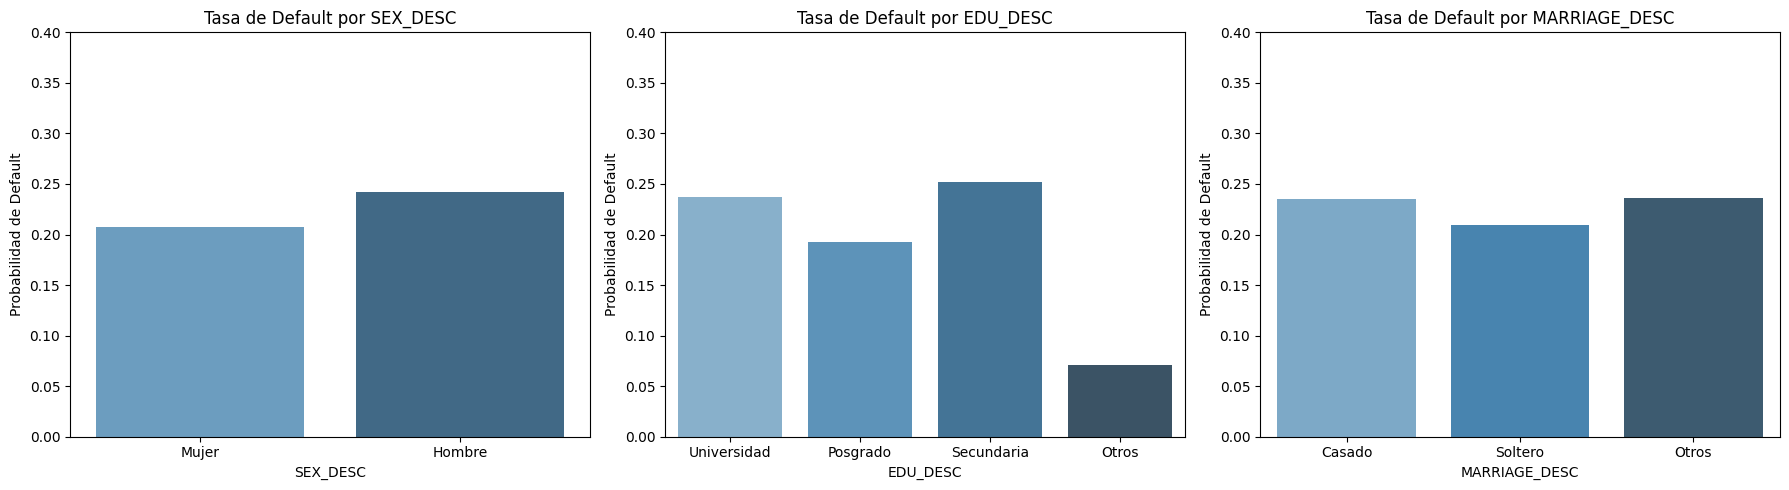

In [25]:


fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(['SEX_DESC', 'EDU_DESC', 'MARRIAGE_DESC']):
    sns.barplot(data=df, x=col, y=target, ax=axes[i], ci=None, palette='Blues_d')
    axes[i].set_title(f'Tasa de Default por {col}')
    axes[i].set_ylabel('Probabilidad de Default')
    axes[i].set_ylim(0, 0.4)

plt.tight_layout()
plt.show()

count    30000.000000
mean        35.485500
std          9.217904
min         21.000000
25%         28.000000
50%         34.000000
75%         41.000000
max         79.000000
Name: AGE, dtype: float64
                                 mean  median       std
default payment next month                             
0                           35.417266    34.0  9.077355
1                           35.725738    34.0  9.693438


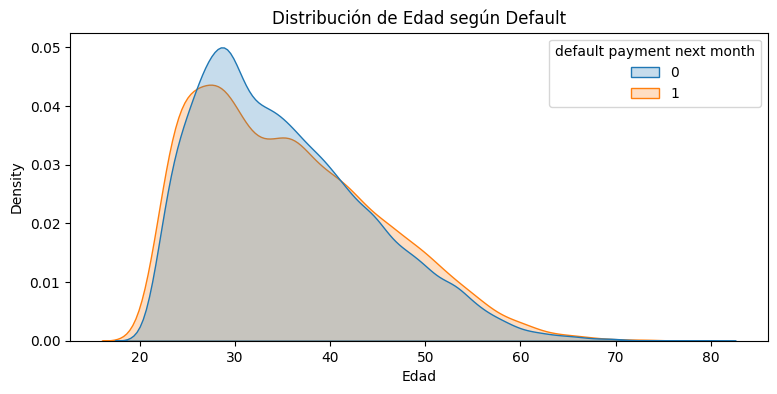

In [26]:
# Estadísticas descriptivas generales
print(df['AGE'].describe())

# Comparar edad promedio según si cayeron en default o no
print(df.groupby(target)['AGE'].agg(['mean', 'median', 'std']))

# Histograma / Gráfico de densidad superpuesto
plt.figure(figsize=(9, 4))
sns.kdeplot(data=df, x='AGE', hue=target, common_norm=False, fill=True)
plt.title('Distribución de Edad según Default')
plt.xlabel('Edad')
plt.show()

/tmp/ipykernel_2676/2898930163.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


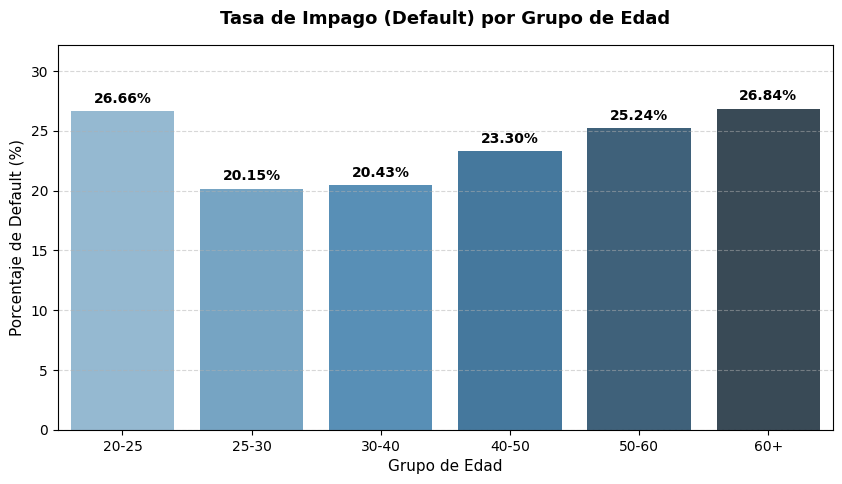

/tmp/ipykernel_2676/2898930163.py:41: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  resumen_edad = df.groupby('RANGO_EDAD')[target].agg(


,Total,Tasa_Default
RANGO_EDAD,,
20-25,3871,26.66%
25-30,7142,20.15%
30-40,10713,20.43%
40-50,6005,23.30%
50-60,1997,25.24%
60+,272,26.84%


In [27]:


# 1. Definir los intervalos solicitados
bins = [20, 25, 30, 40, 50, 60, 100]
labels = ['20-25', '25-30', '30-40', '40-50', '50-60', '60+']

# Creamos la columna agrupada (include_lowest=True incluye a quienes tengan 20 años)
df['RANGO_EDAD'] = pd.cut(df['AGE'], bins=bins, labels=labels, right=True, include_lowest=True)

# 2. Calcular el porcentaje de default por rango etario
target = 'default payment next month'
tasa_edad = df.groupby('RANGO_EDAD', observed=False)[target].mean().reset_index()
tasa_edad['Tasa_%'] = tasa_edad[target] * 100

# 3. Crear el gráfico de barras
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=tasa_edad,
    x='RANGO_EDAD',
    y='Tasa_%',
    palette='Blues_d'
)

# 4. Agregar el número de porcentaje arriba de cada barra
for p in ax.patches:
    altura = p.get_height()
    ax.annotate(f'{altura:.2f}%',
                (p.get_x() + p.get_width() / 2., altura),
                ha='center', va='bottom',
                fontsize=10, fontweight='bold',
                xytext=(0, 4), textcoords='offset points')

# Estética del gráfico
plt.title('Tasa de Impago (Default) por Grupo de Edad', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Grupo de Edad', fontsize=11)
plt.ylabel('Porcentaje de Default (%)', fontsize=11)
plt.ylim(0, tasa_edad['Tasa_%'].max() * 1.2)  # Espacio superior para que entren las etiquetas
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

# Tasa de default por rango de edad
resumen_edad = df.groupby('RANGO_EDAD')[target].agg(
    Total='count',
    Tasa_Default=lambda x: f"{(x.mean() * 100):.2f}%"
)
display(resumen_edad)



# Feature Engineering

voy a crear 4 variables para ver como se comportan los clientes.

*   Tasa de utilizacion de credito: que % de su tarjeta tiene ocupado el cliente.
*   Proporcion de pago de deuda: para distinguir si solo efectua el pago minimo, o que % del pago total.

*   Tendencia de Crecimiento de la Deuda.
*   Historial de Moras acumuladas.







In [28]:


pay_cols = ['PAY_1', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']

# 1. Tasa de utilización del límite de crédito (Septiembre)
df['UTILIZACION_LIMITE'] = df['BILL_AMT1'] / df['LIMIT_BAL']


# 2. Ratio de Pago (Qué % pagó de su deuda anterior)
# Se maneja el caso de factura <= 0 para evitar divisiones por cero
df['RATIO_PAGO_1'] = np.where(
    df['BILL_AMT2'] > 0,
    df['PAY_AMT1'] / df['BILL_AMT2'],
    1.0 # Si no debía nada o tenía saldo a favor, se considera cubierto
)
# Recortamos valores extremos atípicos (entre 0 y 2) para gráficos limpios
df['RATIO_PAGO_1'] = df['RATIO_PAGO_1'].clip(0, 2)

# 3. Tendencia de la deuda (Septiembre vs Abril)
df['TENDENCIA_DEUDA'] = df['BILL_AMT1'] - df['BILL_AMT6']

# 4. Historial acumulado de moras (en los 6 meses)

# Cantidad de meses en que el cliente tuvo demora (valores mayores a 0)
df['CANT_MESES_MORA'] = (df[pay_cols] > 0).sum(axis=1)

# Máximo retraso observado en todo el semestre
df['MAX_MORA'] = df[pay_cols].max(axis=1)

# Vista previa de las nuevas columnas creadas
nuevas_vars = ['UTILIZACION_LIMITE', 'RATIO_PAGO_1', 'TENDENCIA_DEUDA', 'CANT_MESES_MORA', 'MAX_MORA']
df[nuevas_vars].head(5)

,UTILIZACION_LIMITE,RATIO_PAGO_1,TENDENCIA_DEUDA,CANT_MESES_MORA,MAX_MORA
0,0.195650,0.000000,3913,2,2
1,0.022350,0.000000,-579,2,2
2,0.324878,0.108220,13690,0,0
3,0.939800,0.041465,17443,0,0
4,0.172340,0.352734,-10514,0,0


Segun investigue en internet, si la utilizacion del limite de tarjeta supera al 80% ya se considera un signo de peligro. Y los bancos lo tienen en cuenta a la hora de otorgar credito. Ahora voy a crear 3 perfiles de cliente en base a su riesgo crediticio.

*   Bajo Riesgo (Confiable): Nunca tuvo atrasos (CANT_MESES_MORA == 0) y no tiene su tarjeta al tope de uso (UTILIZACION_LIMITE <= 0.80).
*   Riesgo Medio (Atención): Tuvo a lo sumo 1 mes de atraso leve o tiene la tarjeta al límite (> 80% de su cupo).
*   Alto Riesgo (Crítico): Tuvo 2 o más meses con atrasos o llegó a acumular mora de 2 o más meses.





In [29]:
# Definimos las condiciones lógicas para cada grupo
condiciones = [
    # 1. Alto Riesgo: 2 o más meses con atraso O mora máxima de 2 o más meses
    (df['CANT_MESES_MORA'] >= 2) | (df['MAX_MORA'] >= 2),

    # 2. Riesgo Medio: 1 mes de atraso O uso excesivo de su tarjeta (>80%)
    (df['CANT_MESES_MORA'] == 1) | (df['UTILIZACION_LIMITE'] > 0.80),

    # 3. Bajo Riesgo: 0 meses de mora y uso moderado de la tarjeta
    (df['CANT_MESES_MORA'] == 0) & (df['UTILIZACION_LIMITE'] <= 0.80)
]

etiquetas = [
    '3. Alto Riesgo (Crítico)',
    '2. Riesgo Medio (Atención)',
    '1. Bajo Riesgo (Confiable)'
]

# Creamos la columna con los grupos
df['PERFIL_CLIENTE'] = np.select(condiciones, etiquetas, default='Sin clasificar')

In [30]:
target = 'default payment next month'

resumen_grupos = df.groupby('PERFIL_CLIENTE', observed=False)[target].agg(
    Total_Clientes='count',
    Casos_Default='sum',
    Tasa_Default=lambda x: f"{(x.mean() * 100):.2f}%",
    Limite_Promedio=lambda x: f"${df.loc[x.index, 'LIMIT_BAL'].mean():,.0f}"
)

resumen_grupos

,Total_Clientes,Casos_Default,Tasa_Default,Limite_Promedio
PERFIL_CLIENTE,,,,
1. Bajo Riesgo (Confiable),14831,1587,10.70%,"$211,605"
2. Riesgo Medio (Atención),6766,1165,17.22%,"$137,997"
3. Alto Riesgo (Crítico),8403,3884,46.22%,"$113,355"


/tmp/ipykernel_2676/3402982493.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


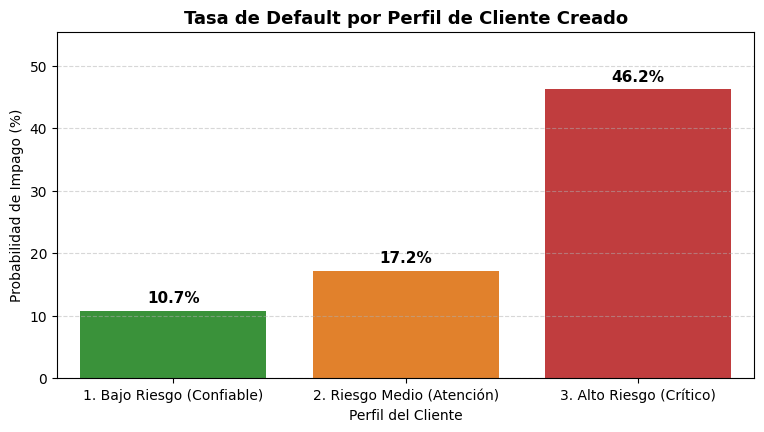

In [31]:
plt.figure(figsize=(9, 4.5))

# Tasa de default en porcentaje
tasa_perfil = df.groupby('PERFIL_CLIENTE', observed=False)[target].mean() * 100

ax = sns.barplot(
    x=tasa_perfil.index,
    y=tasa_perfil.values,
    palette=['#2ca02c', '#ff7f0e', '#d62728'] # Verde, Naranja, Rojo
)

for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=11, fontweight='bold',
                xytext=(0, 4), textcoords='offset points')

plt.title('Tasa de Default por Perfil de Cliente Creado', fontsize=13, fontweight='bold')
plt.xlabel('Perfil del Cliente')
plt.ylabel('Probabilidad de Impago (%)')
plt.ylim(0, max(tasa_perfil.values) * 1.2)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

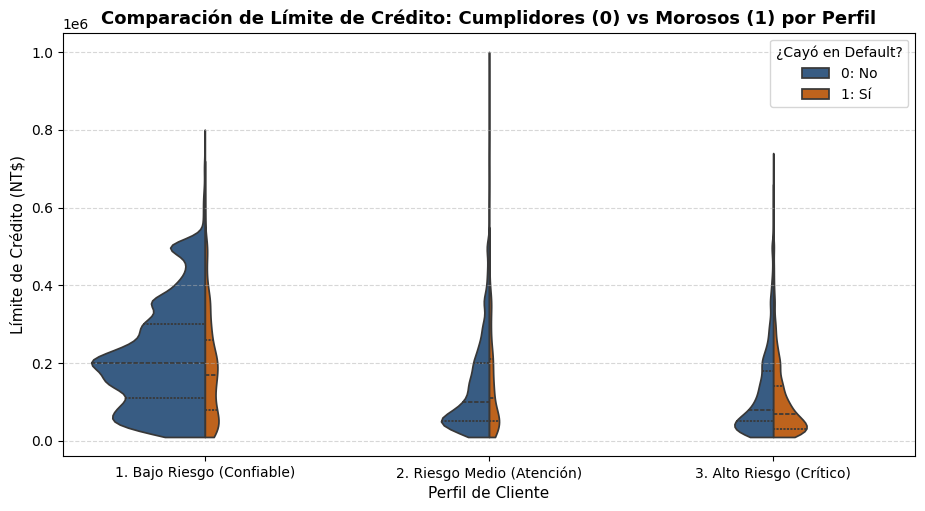

In [32]:
plt.figure(figsize=(11, 5.5))

target = 'default payment next month'

# Aseguramos que la columna PERFIL_CLIENTE exista antes de graficar
if 'PERFIL_CLIENTE' not in df.columns:
    import numpy as np
    pay_cols = ['PAY_1', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']

    # Calculamos de forma interna las variables necesarias si no existen
    if 'CANT_MESES_MORA' not in df.columns:
        df['CANT_MESES_MORA'] = (df[pay_cols] > 0).sum(axis=1)
    if 'MAX_MORA' not in df.columns:
        df['MAX_MORA'] = df[pay_cols].max(axis=1)
    if 'UTILIZACION_LIMITE' not in df.columns:
        df['UTILIZACION_LIMITE'] = df['BILL_AMT1'] / df['LIMIT_BAL']

    condiciones = [
        (df['CANT_MESES_MORA'] >= 2) | (df['MAX_MORA'] >= 2),
        (df['CANT_MESES_MORA'] == 1) | (df['UTILIZACION_LIMITE'] > 0.80),
        (df['CANT_MESES_MORA'] == 0) & (df['UTILIZACION_LIMITE'] <= 0.80)
    ]
    etiquetas = [
        '3. Alto Riesgo (Crítico)',
        '2. Riesgo Medio (Atención)',
        '1. Bajo Riesgo (Confiable)'
    ]
    df['PERFIL_CLIENTE'] = np.select(condiciones, etiquetas, default='Sin clasificar')

# Definimos el orden de los perfiles para solucionar el NameError
orden_perfiles = [
    '1. Bajo Riesgo (Confiable)',
    '2. Riesgo Medio (Atención)',
    '3. Alto Riesgo (Crítico)'
]

ax = sns.violinplot(
    data=df,
    x='PERFIL_CLIENTE',
    y='LIMIT_BAL',
    hue=target,
    order=orden_perfiles,
    split=True,           # Divide el violín en dos mitades
    palette={0: '#2b5c8f', 1: '#d95f02'}, # Azul (No Default) vs Naranja (Default)
    inner='quartile',     # Muestra las líneas de los cuartiles 25%, 50% y 75%
    cut=0,
    density_norm='count', # Escala el ancho según la cantidad real de clientes
    common_norm=True      # Hace que la escala sea global en todo el gráfico
)

plt.title('Comparación de Límite de Crédito: Cumplidores (0) vs Morosos (1) por Perfil', fontsize=13, fontweight='bold')
plt.xlabel('Perfil de Cliente', fontsize=11)
plt.ylabel('Límite de Crédito (NT$)', fontsize=11)

# Forma segura de cambiar los textos de la leyenda sin perder los colores originales
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles=handles, title='¿Cayó en Default?', loc='upper right', labels=['0: No', '1: Sí'])

plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

## ¿Con esto que se puede recomendar?

*   Al grupo Bajo Riesgo: ofrecer aumentos de límite de crédito o beneficios.
*   Al grupo Riesgo Medio: enviar recordatorios de pago preventivos.
*   Al grupo Alto Riesgo: reducir su cupo o frenar nuevas compras.






# Analisis exploratorio avanzado y Correlaciones

## Diagnóstico del Desbalance de Clases:
En problemas de crédito, los clientes que
no pagan son una minoría. Si el 78% de los clientes son buenos pagadores, un modelo ingenuo que prediga siempre "este cliente pagará" tendría un 78% de exactitud (accuracy), pero sería un fracaso financiero porque no detectaría a ningún moroso.

No Default (0): 23,364 clientes (77.88%)
Default    (1): 6,636 clientes (22.12%)


/tmp/ipykernel_2676/3892123492.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['No Default (0)', 'Default (1)'], y=conteo.values, palette=['#2b5c8f', '#d95f02'], ax=ax)


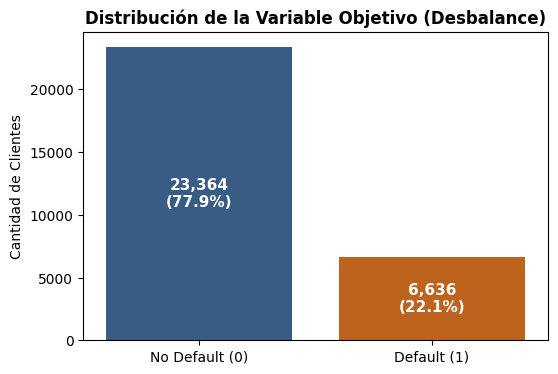

In [33]:
target = 'default payment next month'

# Conteo y proporciones
conteo = df[target].value_counts()
porcentajes = df[target].value_counts(normalize=True) * 100

print(f"No Default (0): {conteo[0]:,} clientes ({porcentajes[0]:.2f}%)")
print(f"Default    (1): {conteo[1]:,} clientes ({porcentajes[1]:.2f}%)")

# Gráfico de barras del desbalance
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=['No Default (0)', 'Default (1)'], y=conteo.values, palette=['#2b5c8f', '#d95f02'], ax=ax)

for p in ax.patches:
    altura = p.get_height()
    pct = (altura / len(df)) * 100
    ax.annotate(f"{int(altura):,}\n({pct:.1f}%)",
                (p.get_x() + p.get_width() / 2., altura / 2),
                ha='center', va='center', color='white', fontweight='bold', fontsize=11)

plt.title('Distribución de la Variable Objetivo (Desbalance)', fontsize=12, fontweight='bold')
plt.ylabel('Cantidad de Clientes')
plt.show()

## Matriz de Correlación y Detección de Multicolinealidad:
Qué variables se relacionan más con el Default?
Qué variables son redundantes entre sí? asi podemos evitar problemas de multicolinealidad

<Figure size 1100x800 with 0 Axes>

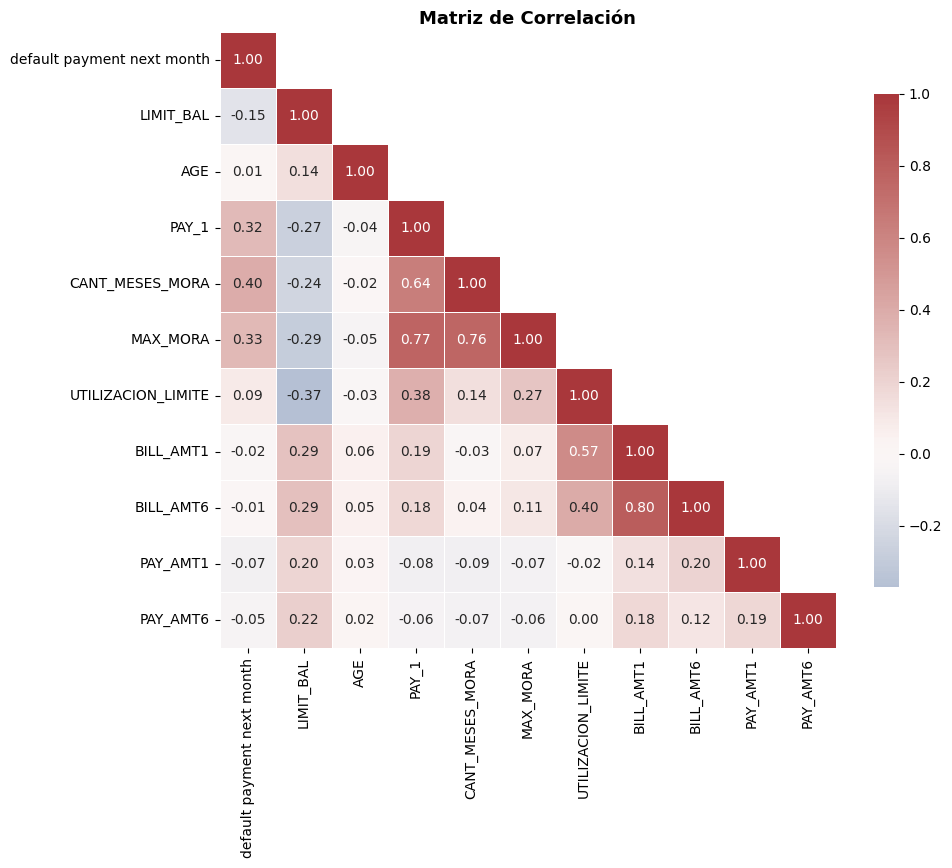

In [34]:
# Seleccionamos un conjunto representativo de variables
columnas_corr = [
    target, 'LIMIT_BAL', 'AGE',
    'PAY_1', 'CANT_MESES_MORA', 'MAX_MORA', 'UTILIZACION_LIMITE',
    'BILL_AMT1','BILL_AMT6',
    'PAY_AMT1', 'PAY_AMT6'
]

plt.figure(figsize=(11, 8))
matriz = df[columnas_corr].corr()

plt.figure(figsize=(10, 8))

# Agregamos k=1 para que la diagonal principal NO se oculte
mask = np.triu(np.ones_like(matriz, dtype=bool), k=1)
sns.heatmap(matriz, mask=mask, annot=True, fmt='.2f', cmap='vlag',
            center=0, square=True, linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Matriz de Correlación', fontsize=13, fontweight='bold')
plt.show()

No incluimos todas las variables porque seria una matriz 25x25. Inviable.

*   En riesgo crediticio, lo que el cliente hizo el mes pasado (PAY_1, Septiembre) es mucho más predictivo de lo que hará el próximo mes que lo que hizo hace 6 meses (PAY_6, Abril).
*   Creamos CANT_MESES_MORA y MAX_MORA.
Esas dos variables ya compactan toda la información de PAY_2, PAY_3, PAY_4, PAY_5 y PAY_6.
*   Redundancia extrema entre las facturas (BILL_AMT)
Las facturas de meses consecutivos tienen una correlación superior al 0.90 entre sí. Elegir BILL_AMT1 (la más reciente) y BILL_AMT6 (la más antigua) alcanza para ver la relación actual y la de largo plazo.




## Análisis Temporal — Evolución de Deuda y Pagos en los 6 Meses:
¿Cómo cambia la facturación y el dinero pagado mes a mes entre un cliente que terminará en default y uno que no?

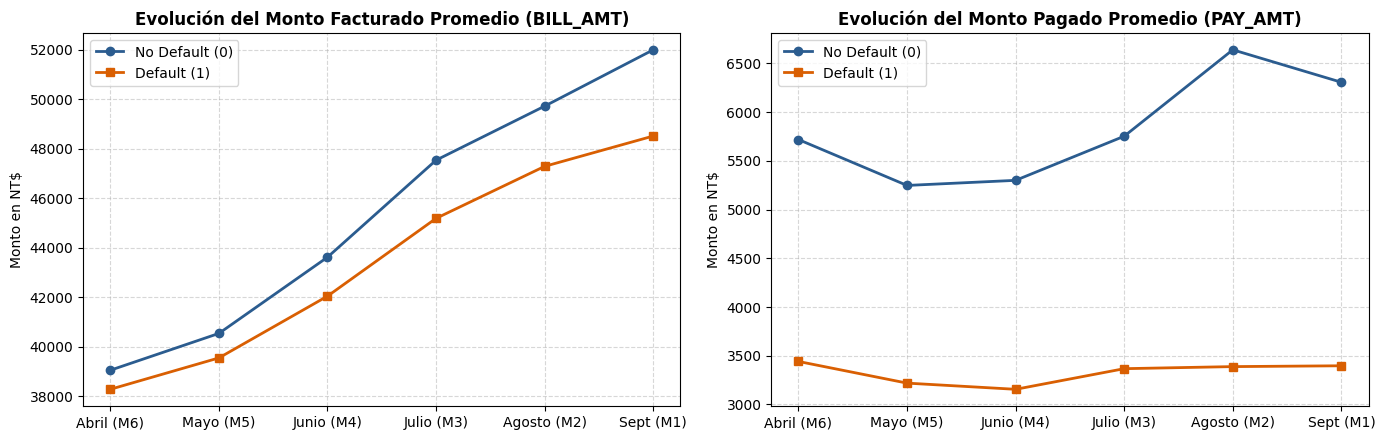

In [35]:
# Calculamos los promedios de factura y pago mes a mes según si cayó en default o no
meses = ['Abril (M6)', 'Mayo (M5)', 'Junio (M4)', 'Julio (M3)', 'Agosto (M2)', 'Sept (M1)']

# Promedio de facturas en orden cronológico (de Abril a Septiembre)
bill_cols = ['BILL_AMT6', 'BILL_AMT5', 'BILL_AMT4', 'BILL_AMT3', 'BILL_AMT2', 'BILL_AMT1']
pay_cols = ['PAY_AMT6', 'PAY_AMT5', 'PAY_AMT4', 'PAY_AMT3', 'PAY_AMT2', 'PAY_AMT1']

evol_bill = df.groupby(target)[bill_cols].mean().T
evol_bill.index = meses

evol_pay = df.groupby(target)[pay_cols].mean().T
evol_pay.index = meses

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharex=True)

# 1. Gráfico de evolución de Facturas
axes[0].plot(meses, evol_bill[0], marker='o', label='No Default (0)', color='#2b5c8f', linewidth=2)
axes[0].plot(meses, evol_bill[1], marker='s', label='Default (1)', color='#d95f02', linewidth=2)
axes[0].set_title('Evolución del Monto Facturado Promedio (BILL_AMT)', fontweight='bold')
axes[0].set_ylabel('Monto en NT$')
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend()

# 2. Gráfico de evolución de Pagos
axes[1].plot(meses, evol_pay[0], marker='o', label='No Default (0)', color='#2b5c8f', linewidth=2)
axes[1].plot(meses, evol_pay[1], marker='s', label='Default (1)', color='#d95f02', linewidth=2)
axes[1].set_title('Evolución del Monto Pagado Promedio (PAY_AMT)', fontweight='bold')
axes[1].set_ylabel('Monto en NT$')
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend()

plt.tight_layout()
plt.show()

Los clientes cumplidores (0) pagan montos significativamente superiores todos los meses ($ 6,000 en promedio).

Los clientes en default (1) pagan casi la mitad ($ 3,000), a pesar de que su deuda facturada se mantiene en niveles similares. Es decir, su capacidad de pago real colapsó meses antes.

## Límite de Crédito (LIMIT_BAL) vs Riesgo:


In [36]:

target = 'default payment next month'

# 1. Definición con 5 tramos (unificando todo lo mayor a 300k)
limite_bins = [0, 50000, 100000, 200000, 300000, np.inf]
limite_labels = ['Hasta 50k', '50k-100k', '100k-200k', '200k-300k', '+300k']

df['RANGO_LIMITE'] = pd.cut(df['LIMIT_BAL'], bins=limite_bins, labels=limite_labels, right=True)

# 2. Tabla resumen completa
tabla_limites = df.groupby('RANGO_LIMITE', observed=False)[target].agg(
    Total_Clientes='count',
    No_Default=lambda x: (x == 0).sum(),
    Default=lambda x: (x == 1).sum(),
    Tasa_Default=lambda x: f"{(x.mean() * 100):.2f}%"
)

tabla_limites['%_del_Total'] = (tabla_limites['Total_Clientes'] / len(df) * 100).map("{:.2f}%".format)

display(tabla_limites)

,Total_Clientes,No_Default,Default,Tasa_Default,%_del_Total
RANGO_LIMITE,,,,,
Hasta 50k,7676,5236,2440,31.79%,25.59%
50k-100k,4822,3578,1244,25.80%,16.07%
100k-200k,7880,6345,1535,19.48%,26.27%
200k-300k,5059,4247,812,16.05%,16.86%
+300k,4563,3958,605,13.26%,15.21%


/tmp/ipykernel_2676/3466218346.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(x=tasa_serie.index, y=tasa_serie.values, ax=axes[0], palette='Blues_r')


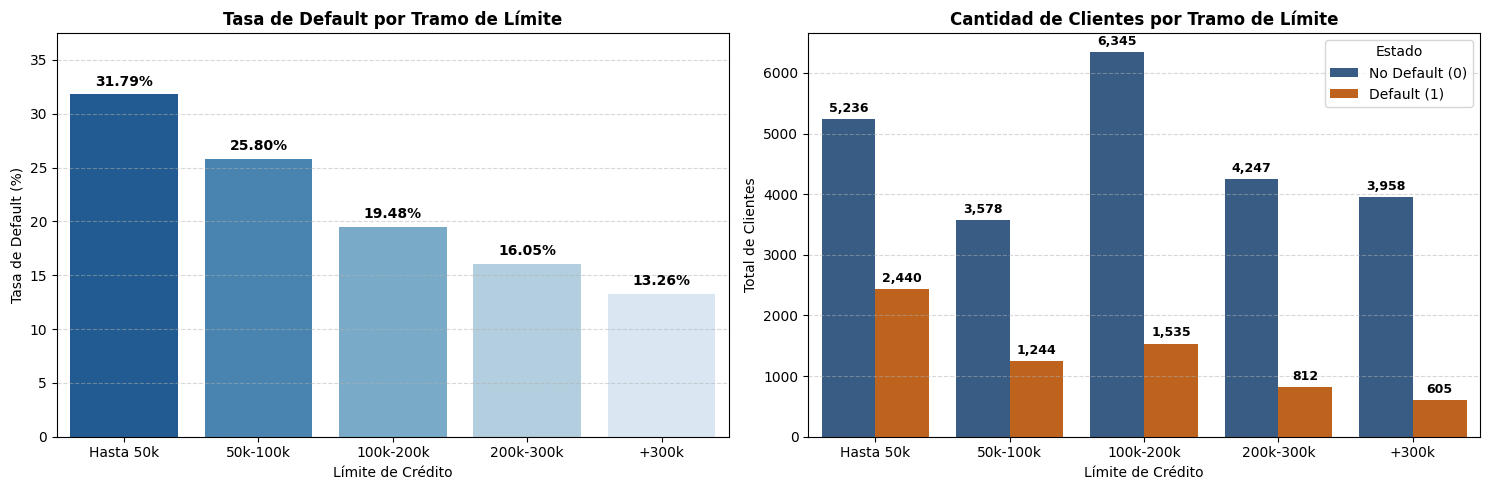

In [37]:

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# -------------------------------------------------------------
# Gráfico 1: Tasa de Default (%) por tramo de límite
# -------------------------------------------------------------
tasa_serie = df.groupby('RANGO_LIMITE', observed=False)[target].mean() * 100

ax1 = sns.barplot(x=tasa_serie.index, y=tasa_serie.values, ax=axes[0], palette='Blues_r')

for p in ax1.patches:
    ax1.annotate(f"{p.get_height():.2f}%",
                 (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='bottom', fontsize=10, fontweight='bold',
                 xytext=(0, 4), textcoords='offset points')

axes[0].set_title('Tasa de Default por Tramo de Límite', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Límite de Crédito')
axes[0].set_ylabel('Tasa de Default (%)')
axes[0].set_ylim(0, tasa_serie.max() * 1.18)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# -------------------------------------------------------------
# Gráfico 2: Cantidad total de clientes (Cumplidores vs Morosos)
# -------------------------------------------------------------
ax2 = sns.countplot(data=df, x='RANGO_LIMITE', hue=target, ax=axes[1], palette=['#2b5c8f', '#d95f02'])

for p in ax2.patches:
    altura = p.get_height()
    if altura > 0:
        ax2.annotate(f"{int(altura):,}",
                     (p.get_x() + p.get_width() / 2., altura),
                     ha='center', va='bottom', fontsize=9, fontweight='bold',
                     xytext=(0, 3), textcoords='offset points')

axes[1].set_title('Cantidad de Clientes por Tramo de Límite', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Límite de Crédito')
axes[1].set_ylabel('Total de Clientes')
axes[1].legend(title='Estado', labels=['No Default (0)', 'Default (1)'])
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Menor cupo, mayor riesgo: Los clientes con límites inferiores a \$ 50.000 duplican la morosidad del segmento superior (> \$ 300.000), pasando de un 14% a un 32% de probabilidad de impago.

El cupo asignado refleja directamente la estabilidad económica previa del cliente, actuando como un predictor temprano de morosidad.

# Agregar conceptos y pruebas de estadistica de la clase 20/10
# Y revisar bien la redaccion y orden de todo en general

In [38]:
from scipy import stats

target = 'default payment next month'

# Separamos los dos grupos
no_default = df.loc[df[target] == 0, 'LIMIT_BAL']
default = df.loc[df[target] == 1, 'LIMIT_BAL']

# 1. Prueba t de Welch (muestras independientes, varianzas distintas)
t_stat, p_val_t = stats.ttest_ind(no_default, default, equal_var=False)

# Diferencia de medias e Intervalo de Confianza al 95%
dif_medias = no_default.mean() - default.mean()
s_dif = np.sqrt(no_default.var(ddof=1)/len(no_default) + default.var(ddof=1)/len(default))
ic_dif = (dif_medias - 1.96 * s_dif, dif_medias + 1.96 * s_dif)

# d de Cohen (Tamaño del efecto)
d_cohen = dif_medias / np.sqrt((no_default.var() + default.var()) / 2)

# 2. Prueba no paramétrica de Mann-Whitney U (robusta a asimetría)
mw_stat, p_val_mw = stats.mannwhitneyu(no_default, default, alternative='two-sided')
prob_sup = mw_stat / (len(no_default) * len(default))  # P(No Default > Default)

print(f"--- Comparación de Límite de Crédito (LIMIT_BAL) ---")
print(f"Media No Default: NT$ {no_default.mean():,.0f} | Mediana: NT$ {no_default.median():,.0f}")
print(f"Media Default:    NT$ {default.mean():,.0f} | Mediana: NT$ {default.median():,.0f}")
print(f"Diferencia: NT$ {dif_medias:,.0f}  [IC 95%: {ic_dif[0]:,.0f} a {ic_dif[1]:,.0f}]")
print(f"t de Welch = {t_stat:.2f} | valor-p = {p_val_t:.1e} (Rechazo H0)")
print(f"d de Cohen = {d_cohen:.2f} (Efecto moderado-pequeño)")
print(f"Mann-Whitney U: P(No Default > Default) = {prob_sup:.2f}")

--- Comparación de Límite de Crédito (LIMIT_BAL) ---
Media No Default: NT$ 178,100 | Mediana: NT$ 150,000
Media Default:    NT$ 130,110 | Mediana: NT$ 90,000
Diferencia: NT$ 47,990  [IC 95%: 44,741 a 51,239]
t de Welch = 28.95 | valor-p = 3.4e-178 (Rechazo H0)
d de Cohen = 0.39 (Efecto moderado-pequeño)
Mann-Whitney U: P(No Default > Default) = 0.62


ANOVA F = 769.0 | valor-p = 0.0e+00
          Multiple Comparison of Means - Tukey HSD, FWER=0.05          
  group1      group2     meandiff  p-adj    lower       upper    reject
-----------------------------------------------------------------------
     Otros    Posgrado  31639.8306   0.0  16465.9213  46813.7399   True
     Otros  Secundaria -54765.9688   0.0 -70305.7744 -39226.1633   True
     Otros Universidad -34253.8017   0.0 -49348.6253 -19158.9781   True
  Posgrado  Secundaria -86405.7994   0.0 -91949.8105 -80861.7884   True
  Posgrado Universidad -65893.6323   0.0  -70029.355 -61757.9096   True
Secundaria Universidad  20512.1671   0.0  15188.4246  25835.9097   True
-----------------------------------------------------------------------


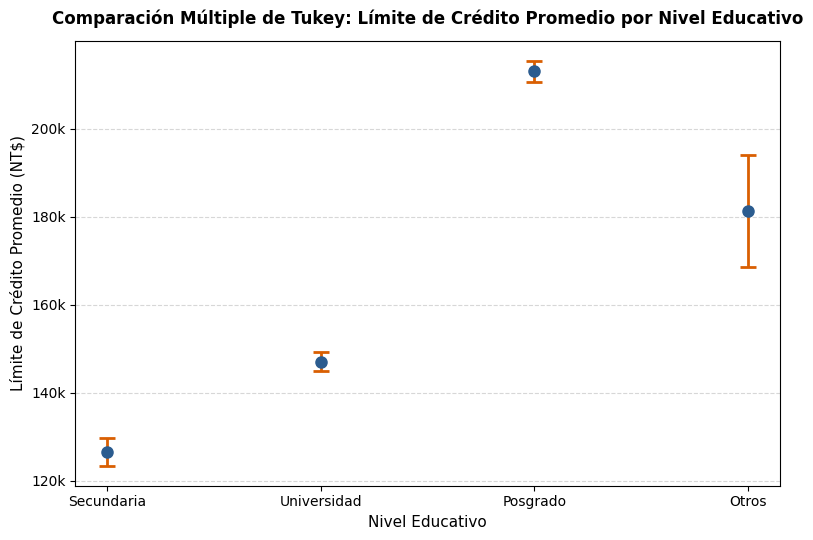

In [40]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# 1. Nuevo orden solicitado en el eje X
grupos_edu = ['Secundaria', 'Universidad', 'Posgrado', 'Otros']
muestras_edu = [df.loc[df['EDU_DESC'] == g, 'LIMIT_BAL'] for g in grupos_edu]

# 2. ANOVA de un factor
anova = stats.f_oneway(*muestras_edu)
print(f"ANOVA F = {anova.statistic:.1f} | valor-p = {anova.pvalue:.1e}")

# 3. Comparaciones múltiples de Tukey HSD
tukey = pairwise_tukeyhsd(endog=df['LIMIT_BAL'], groups=df['EDU_DESC'], alpha=0.05)
print(tukey)

# -------------------------------------------------------------
# 4. Gráfico Vertical con el nuevo orden en X
# -------------------------------------------------------------
# Llamamos a plot_simultaneous internamente para que calcule los intervalos de Tukey
fig_temp = tukey.plot_simultaneous()
plt.close(fig_temp)  # Cerramos el gráfico horizontal para no duplicar

# Mapeamos cada grupo con su media y su margen de error (halfwidth) de Tukey
datos_tukey = {
    grupo: (df.loc[df['EDU_DESC'] == grupo, 'LIMIT_BAL'].mean(), hw)
    for grupo, hw in zip(tukey.groupsunique, tukey.halfwidths)
}

# Extraemos exactamente en el nuevo orden
medias_y = [datos_tukey[g][0] for g in grupos_edu]
errores_y = [datos_tukey[g][1] for g in grupos_edu]

# Dibujamos el gráfico vertical
plt.figure(figsize=(8, 5.5))
ax = plt.subplot(111)

ax.errorbar(
    x=grupos_edu,
    y=medias_y,
    yerr=errores_y,
    fmt='o',
    color='#2b5c8f',        # Color del punto (Media)
    ecolor='#d95f02',       # Color del intervalo Tukey (95%)
    elinewidth=2,
    capsize=6,
    capthick=2,
    markersize=8
)

# Formato de miles (k) en el eje Y
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x/1000):,}k"))

plt.title("Comparación Múltiple de Tukey: Límite de Crédito Promedio por Nivel Educativo", fontsize=12, fontweight='bold', pad=12)
plt.xlabel("Nivel Educativo", fontsize=11)
plt.ylabel("Límite de Crédito Promedio (NT$)", fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

¿Qué representa cada elemento en este gráfico?

El punto azul (•): Es la Media muestral (
𝑥
ˉ
) del límite de crédito de ese grupo (el promedio aritmético, no la mediana).

Las barras (líneas con topes): No son los cuartiles.
Son los Intervalos de Confianza Simultáneos de Tukey (al 95%) para la media poblacional.
Representan el rango de valores donde se encuentra el verdadero límite promedio de ese grupo en la población general, con un 95% de seguridad y corrigiendo el error por comparar varios grupos a la vez.

Chi-cuadrado = 160.41 | gl = 3 | valor-p = 1.5e-34
V de Cramér = 0.073 (Asociación estadísticamente significativa)

--- Residuos Estandarizados Ajustados de Haberman ---
(|z| > 1.96 indica apartamiento significativo al 5%)


,No Default (0),Default (1)
EDU_DESC,,
Otros,7.92,-7.92
Posgrado,8.89,-8.89
Secundaria,-5.61,5.61
Universidad,-6.32,6.32


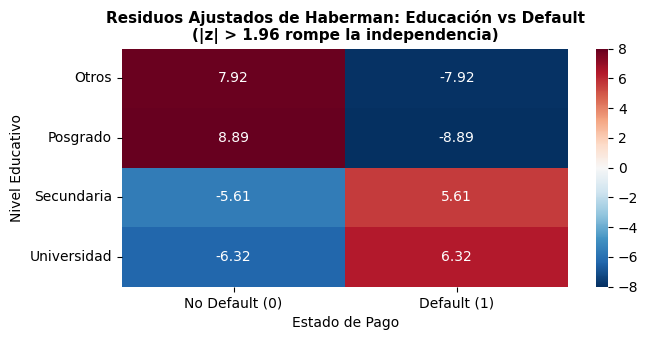

In [41]:
# 1. Tabla de contingencia observada (sin totales)
observadas = pd.crosstab(df['EDU_DESC'], df[target])
observadas.columns = ['No Default (0)', 'Default (1)']

# 2. Prueba Chi-cuadrado y V de Cramér
chi2, p_val, gl, esperadas_arr = stats.chi2_contingency(observadas)
total = observadas.values.sum()
cramer_v = np.sqrt(chi2 / (total * (min(observadas.shape) - 1)))

print(f"Chi-cuadrado = {chi2:.2f} | gl = {gl} | valor-p = {p_val:.1e}")
print(f"V de Cramér = {cramer_v:.3f} (Asociación estadísticamente significativa)")

# 3. Cálculo de Residuos Estandarizados Ajustados de Haberman (z_ij)
esperadas = pd.DataFrame(esperadas_arr, index=observadas.index, columns=observadas.columns)
prop_fila = observadas.sum(axis=1).to_numpy()[:, None] / total
prop_columna = observadas.sum(axis=0).to_numpy()[None, :] / total

residuos_ajustados = (observadas - esperadas) / np.sqrt(
    esperadas * (1 - prop_fila) * (1 - prop_columna)
)

print("\n--- Residuos Estandarizados Ajustados de Haberman ---")
print("(|z| > 1.96 indica apartamiento significativo al 5%)")
display(residuos_ajustados.round(2))

# 4. Heatmap visual idéntico al de la clase
plt.figure(figsize=(7, 3.5))
sns.heatmap(residuos_ajustados, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-8, vmax=8)
plt.title("Residuos Ajustados de Haberman: Educación vs Default\n(|z| > 1.96 rompe la independencia)", fontsize=11, fontweight='bold')
plt.ylabel("Nivel Educativo")
plt.xlabel("Estado de Pago")
plt.tight_layout()
plt.show()

¿Cómo funciona matemáticamente (en palabras simples)?

Para cada celda de la tabla (por ejemplo: Secundaria y Cayó en Default), la computadora compara dos números:


O (Observados): Cuántos clientes reales hay en esa celda.

E (Esperados): Cuántos clientes debería haber habido si el nivel educativo y el default no tuvieran ninguna relación (por puro azar).

Si restamos
O−E:
Si da positivo, hay más morosos de lo esperado.
Si da negativo, hay menos morosos de lo esperado.



Tasa Default Hombres: 24.17% (n = 11,888)
Tasa Default Mujeres: 20.78% (n = 18,112)
Diferencia: 3.39 puntos porcentuales
IC 95% de la diferencia: [2.42% ; 4.36%]
Estadístico Z = 6.92 | valor-p = 4.5e-12


/tmp/ipykernel_2676/3598385847.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


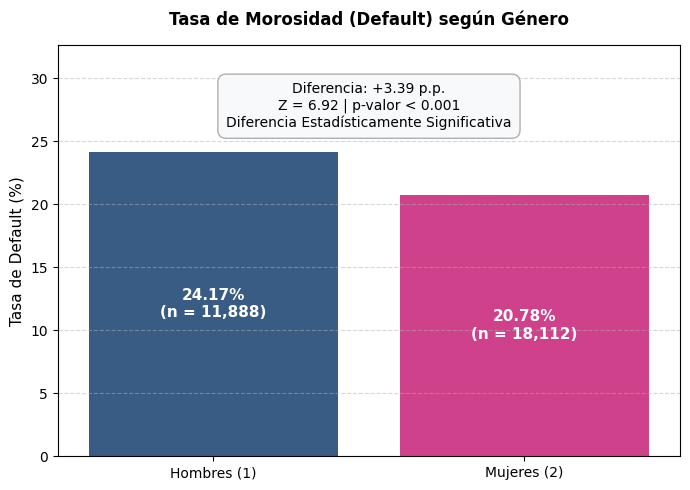

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.proportion import confint_proportions_2indep, proportions_ztest

# 1. Filtrar por género (1 = Hombre, 2 = Mujer)
hombres = df[df['SEX'] == 1][target]
mujeres = df[df['SEX'] == 2][target]

count = [hombres.sum(), mujeres.sum()]      # Cantidad de defaults
nobs = [len(hombres), len(mujeres)]         # Totales por grupo

# 2. Prueba Z de dos proporciones
z_stat, p_val = proportions_ztest(count, nobs)

# Intervalo de confianza de la diferencia de proporciones (al 95%)
ic_inf, ic_sup = confint_proportions_2indep(count[0], nobs[0], count[1], nobs[1], method='score')

tasa_h = hombres.mean() * 100
tasa_m = mujeres.mean() * 100

print(f"Tasa Default Hombres: {tasa_h:.2f}% (n = {len(hombres):,})")
print(f"Tasa Default Mujeres: {tasa_m:.2f}% (n = {len(mujeres):,})")
print(f"Diferencia: {tasa_h - tasa_m:.2f} puntos porcentuales")
print(f"IC 95% de la diferencia: [{ic_inf*100:.2f}% ; {ic_sup*100:.2f}%]")
print(f"Estadístico Z = {z_stat:.2f} | valor-p = {p_val:.1e}")

# -------------------------------------------------------------
# 3. Gráfico para lectura rápida de un vistazo
# -------------------------------------------------------------
plt.figure(figsize=(7, 5))

generos = ['Hombres (1)', 'Mujeres (2)']
tasas = [tasa_h, tasa_m]

ax = sns.barplot(
    x=generos,
    y=tasas,
    palette=['#2b5c8f', '#e7298a'] # Azul para hombres, Rosa/Fucsia para mujeres
)

# Etiquetas con porcentaje y total de muestra (n) adentro de cada barra
for i, p in enumerate(ax.patches):
    altura = p.get_height()
    ax.annotate(f"{altura:.2f}%\n(n = {nobs[i]:,})",
                (p.get_x() + p.get_width() / 2., altura / 2),
                ha='center', va='center', color='white', fontweight='bold', fontsize=11)

# Cuadro de texto flotante con el resultado del Test Z
cartel = (f"Diferencia: +{tasa_h - tasa_m:.2f} p.p.\n"
          f"Z = {z_stat:.2f} | p-valor < 0.001\n"
          f"Diferencia Estadísticamente Significativa")

plt.text(0.5, max(tasas) * 1.15, cartel, ha='center', va='center',
         fontsize=10, bbox=dict(boxstyle='round,pad=0.6', facecolor='#f8f9fa', edgecolor='#b0b0b0'))

plt.title('Tasa de Morosidad (Default) según Género', fontsize=12, fontweight='bold', pad=15)
plt.ylabel('Tasa de Default (%)', fontsize=11)
plt.ylim(0, max(tasas) * 1.35)  # Espacio superior para el cartel explicativo
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Al dar un valor-p muy inferior a 0.05, confirmas con rigor estadístico que los hombres tienen una tasa de impago sistemáticamente más alta que las mujeres en este banco.

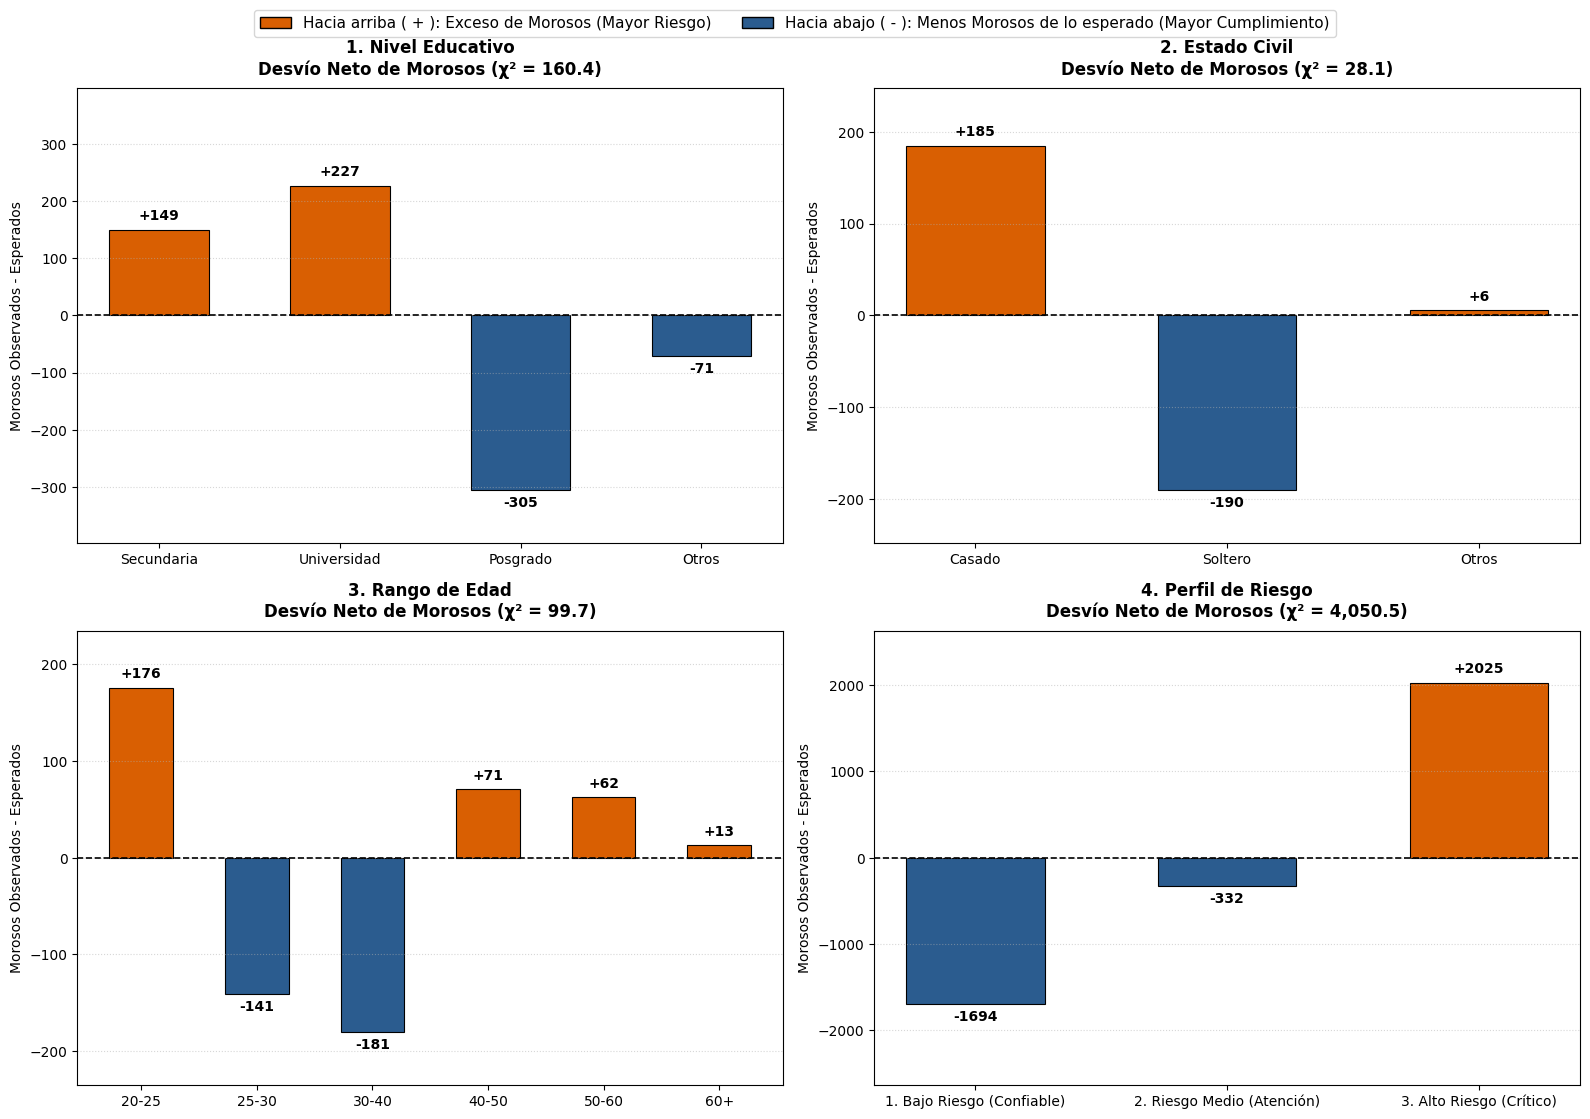

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy import stats

target = 'default payment next month'

config_variables = [
    {
        'columna': 'EDU_DESC',
        'titulo': '1. Nivel Educativo',
        'orden': ['Secundaria', 'Universidad', 'Posgrado', 'Otros']
    },
    {
        'columna': 'MARRIAGE_DESC',
        'titulo': '2. Estado Civil',
        'orden': ['Casado', 'Soltero', 'Otros']
    },
    {
        'columna': 'RANGO_EDAD',
        'titulo': '3. Rango de Edad',
        'orden': ['20-25', '25-30', '30-40', '40-50', '50-60', '60+']
    },
    {
        'columna': 'PERFIL_CLIENTE',
        'titulo': '4. Perfil de Riesgo',
        'orden': ['1. Bajo Riesgo (Confiable)', '2. Riesgo Medio (Atención)', '3. Alto Riesgo (Crítico)']
    }
]

# Grilla de 2 filas x 2 columnas
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
axes = axes.flatten()

for i, cfg in enumerate(config_variables):
    ax = axes[i]
    col = cfg['columna']
    nombre = cfg['titulo']
    orden = cfg['orden']

    # 1. Tabla Observada
    obs = pd.crosstab(df[col], df[target])
    obs.columns = ['No Default (0)', 'Default (1)']
    if orden:
        obs = obs.reindex([c for c in orden if c in obs.index])

    # 2. Frecuencias Esperadas bajo Independencia
    chi2, p_val, dof, expected = stats.chi2_contingency(obs)
    exp_df = pd.DataFrame(expected, index=obs.index, columns=obs.columns)

    # 3. DIFERENCIA NETA EXCLUSIVA DE MOROSOS (Default)
    # Si > 0: Hay más morosos de lo esperado por azar
    # Si < 0: Hay menos morosos de lo esperado por azar
    dif_default = obs['Default (1)'] - exp_df['Default (1)']

    # 4. Color dinámico: Naranja si sube (riesgo), Azul si baja (seguridad)
    colores_barras = ['#d95f02' if val > 0 else '#2b5c8f' for val in dif_default.values]

    # 5. Dibujar la barra única neta
    bars = ax.bar(dif_default.index, dif_default.values, color=colores_barras, edgecolor='black', linewidth=0.8, width=0.55)

    # Línea de referencia en CERO (Independencia teórica)
    ax.axhline(0, color='black', linewidth=1.2, linestyle='--')

    # Anotar el número exacto (+ o -) sobre/debajo de la barra
    for bar in bars:
        val = bar.get_height()
        if not np.isnan(val) and abs(val) > 0.5:
            signo = "+" if val > 0 else ""
            offset = 5 if val >= 0 else -14
            ax.annotate(f"{signo}{val:.0f}",
                        (bar.get_x() + bar.get_width() / 2., val),
                        ha='center', va='bottom', fontsize=10, fontweight='bold',
                        xytext=(0, offset), textcoords='offset points')

    ax.set_title(f"{nombre}\nDesvío Neto de Morosos (χ² = {chi2:,.1f})",
                 fontsize=12, fontweight='bold', pad=10)
    ax.set_ylabel('Morosos Observados - Esperados', fontsize=10)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=0)
    ax.grid(axis='y', linestyle=':', alpha=0.5)

    # Límites verticales equilibrados
    lim_y = max(abs(dif_default.min()), abs(dif_default.max())) * 1.3
    ax.set_ylim(-lim_y, lim_y)

# Leyenda superior general
legend_elements = [
    Patch(facecolor='#d95f02', edgecolor='black', label='Hacia arriba ( + ): Exceso de Morosos (Mayor Riesgo)'),
    Patch(facecolor='#2b5c8f', edgecolor='black', label='Hacia abajo ( - ): Menos Morosos de lo esperado (Mayor Cumplimiento)')
]
fig.legend(handles=legend_elements, loc='upper center', bbox_to_anchor=(0.5, 1.02), ncol=2, fontsize=11, frameon=True)

plt.tight_layout()
plt.show()

Tener en cuenta que hay 30k observaciones, 200 es un volumen muy bajo, no morir de nominalidad

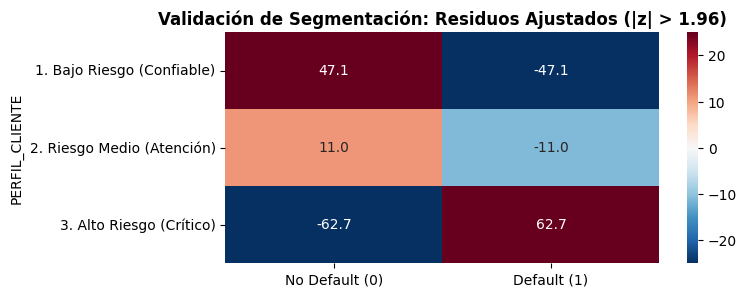

In [44]:
# Tabla observada entre tu perfil creado y el default
obs_perfil = pd.crosstab(df['PERFIL_CLIENTE'], df[target])
obs_perfil.columns = ['No Default (0)', 'Default (1)']

total = obs_perfil.values.sum()
esperadas = np.outer(obs_perfil.sum(axis=1), obs_perfil.sum(axis=0)) / total

prop_f = obs_perfil.sum(axis=1).to_numpy()[:, None] / total
prop_c = obs_perfil.sum(axis=0).to_numpy()[None, :] / total
residuos_perfil = (obs_perfil - esperadas) / np.sqrt(esperadas * (1 - prop_f) * (1 - prop_c))

plt.figure(figsize=(7, 3))
sns.heatmap(residuos_perfil, annot=True, fmt='.1f', cmap='RdBu_r', center=0, vmin=-25, vmax=25)
plt.title("Validación de Segmentación: Residuos Ajustados (|z| > 1.96)", fontweight='bold')
plt.show()

Los valores estan expresados en Z. Estar segmentando en 40 Z es mucho (bueno)

In [45]:
from statsmodels.stats.proportion import proportion_confint

exitos = df[target].sum()
n = len(df)
proporcion = exitos / n

# Intervalo de Wilson (el método más robusto para proporciones)
ic_inf, ic_sup = proportion_confint(count=exitos, nobs=n, alpha=0.05, method='wilson')

print(f"Tasa puntual de Default: {proporcion * 100:.2f}%")
print(f"IC 95% para la proporción poblacional: [{ic_inf * 100:.2f}% ; {ic_sup * 100:.2f}%]")

Tasa puntual de Default: 22.12%
IC 95% para la proporción poblacional: [21.65% ; 22.59%]


Con un 95% de confianza, la verdadera proporción de morosidad de la población de clientes de este banco está acotada en un margen muy estrecho entre 21.65% y 22.59%.